In [2]:
import math
import random
import re
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence
from datasets import load_dataset

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")

print("Device:", DEVICE)

# Notebook-friendly defaults
MAX_TRAIN_EXAMPLES = 12000  # Set to None to use all training examples
MAX_EVAL_EXAMPLES = 1000
BATCH_SIZE = 64
EMBEDDING_DIM = 64
HIDDEN_SIZE = 128
DROPOUT = 0.2
EPOCHS = 8
LEARNING_RATE = 0.001
MAX_DECODE_LEN = 35

PAD_TOKEN = "<pad>"
UNK_TOKEN = "<unk>"
SOS_TOKEN = "<sos>"
EOS_TOKEN = "<eos>"
SPECIAL_TOKENS = [PAD_TOKEN, UNK_TOKEN, SOS_TOKEN, EOS_TOKEN]


Device: mps


In [3]:
dataset = load_dataset("bentrevett/multi30k")
print(dataset)
print("Available columns:", dataset["train"].column_names)
print("Example row:", dataset["train"][0])


README.md:   0%|          | 0.00/1.15k [00:00<?, ?B/s]

train.jsonl:   0%|          | 0.00/4.60M [00:00<?, ?B/s]

val.jsonl:   0%|          | 0.00/164k [00:00<?, ?B/s]

test.jsonl:   0%|          | 0.00/156k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/29000 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/1014 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['en', 'de'],
        num_rows: 29000
    })
    validation: Dataset({
        features: ['en', 'de'],
        num_rows: 1014
    })
    test: Dataset({
        features: ['en', 'de'],
        num_rows: 1000
    })
})
Available columns: ['en', 'de']
Example row: {'en': 'Two young, White males are outside near many bushes.', 'de': 'Zwei junge weiße Männer sind im Freien in der Nähe vieler Büsche.'}


In [4]:
first_row = dataset["train"][0]
columns = set(first_row.keys())

if {"en", "de"}.issubset(columns):
    SRC_KEY, TGT_KEY = "en", "de"
elif {"english", "german"}.issubset(columns):
    SRC_KEY, TGT_KEY = "english", "german"
else:
    raise ValueError(f"Could not identify English/German columns: {columns}")

VALID_SPLIT = "validation" if "validation" in dataset else "valid"
TEST_SPLIT = "test" if "test" in dataset else VALID_SPLIT

def get_pairs(split_name, limit=None):
    split = dataset[split_name]
    n = len(split) if limit is None else min(len(split), limit)
    result = []
    for row in split.select(range(n)):
        src = str(row[SRC_KEY]).strip()
        tgt = str(row[TGT_KEY]).strip()
        if src and tgt:
            result.append((src, tgt))
    return result

train_pairs = get_pairs("train", MAX_TRAIN_EXAMPLES)
valid_pairs = get_pairs(VALID_SPLIT, MAX_EVAL_EXAMPLES)
test_pairs = get_pairs(TEST_SPLIT, MAX_EVAL_EXAMPLES)

print(f"Train pairs: {len(train_pairs):,}")
print(f"Validation pairs: {len(valid_pairs):,}")
print(f"Test pairs: {len(test_pairs):,}")
print("\nExample:")
print("EN:", train_pairs[0][0])
print("DE:", train_pairs[0][1])


Train pairs: 12,000
Validation pairs: 1,000
Test pairs: 1,000

Example:
EN: Two young, White males are outside near many bushes.
DE: Zwei junge weiße Männer sind im Freien in der Nähe vieler Büsche.


In [5]:
def tokenize(text):
    return re.findall(r"\\w+|[^\\w\\s]", text.lower().strip(), flags=re.UNICODE)

class Vocabulary:
    def __init__(self, sentences, min_freq=2):
        counts = Counter()
        for sentence in sentences:
            counts.update(tokenize(sentence))
        words = sorted(
            word for word, count in counts.items()
            if count >= min_freq and word not in SPECIAL_TOKENS
        )
        self.itos = SPECIAL_TOKENS + words
        self.stoi = {word: idx for idx, word in enumerate(self.itos)}
        self.pad_id = self.stoi[PAD_TOKEN]
        self.unk_id = self.stoi[UNK_TOKEN]
        self.sos_id = self.stoi[SOS_TOKEN]
        self.eos_id = self.stoi[EOS_TOKEN]

    def encode(self, sentence, add_sos=False, add_eos=False):
        ids = [self.stoi.get(token, self.unk_id) for token in tokenize(sentence)]
        if add_sos:
            ids = [self.sos_id] + ids
        if add_eos:
            ids = ids + [self.eos_id]
        return ids

    def decode(self, ids):
        words = []
        for idx in ids:
            word = self.itos[int(idx)]
            if word == EOS_TOKEN:
                break
            if word not in (PAD_TOKEN, SOS_TOKEN):
                words.append(word)
        text = " ".join(words)
        return re.sub(r"\\s+([.,!?;:])", r"\\1", text)

src_vocab = Vocabulary([src for src, _ in train_pairs])
tgt_vocab = Vocabulary([tgt for _, tgt in train_pairs])

print("Source vocabulary:", len(src_vocab.itos))
print("Target vocabulary:", len(tgt_vocab.itos))

example_source = train_pairs[0][0]
example_ids = src_vocab.encode(example_source, add_eos=True)
print("\nText:", example_source)
print("Tokens:", tokenize(example_source))
print("IDs (+ EOS):", example_ids)


Source vocabulary: 50
Target vocabulary: 61

Text: Two young, White males are outside near many bushes.
Tokens: ['t', 'o', ' ', 'y', 'o', 'u', 'n', 'g', ',', ' ', 'h', 'i', 't', 'e', ' ', 'm', 'a', 'l', 'e', ' ', 'a', 'r', 'e', ' ', 'o', 'u', 't', 'i', 'd', 'e', ' ', 'n', 'e', 'a', 'r', ' ', 'm', 'a', 'n', 'y', ' ', 'b', 'u', 'h', 'e', '.']
IDs (+ EOS): [44, 40, 4, 48, 40, 45, 39, 32, 12, 4, 33, 34, 44, 30, 4, 38, 26, 37, 30, 4, 26, 43, 30, 4, 40, 45, 44, 34, 29, 30, 4, 39, 30, 26, 43, 4, 38, 26, 39, 48, 4, 27, 45, 33, 30, 14, 3]


In [6]:
class TranslationDataset(Dataset):
    def __init__(self, pairs, src_vocab, tgt_vocab):
        self.items = []
        for src_text, tgt_text in pairs:
            src_ids = src_vocab.encode(src_text, add_eos=True)
            tgt_ids = tgt_vocab.encode(tgt_text, add_sos=True, add_eos=True)
            self.items.append((src_ids, tgt_ids, src_text, tgt_text))

    def __len__(self):
        return len(self.items)

    def __getitem__(self, idx):
        return self.items[idx]

def make_collate_fn(src_vocab, tgt_vocab):
    def collate(batch):
        src_lists, tgt_lists, src_texts, tgt_texts = zip(*batch)
        src_lengths = torch.tensor([len(x) for x in src_lists], dtype=torch.long)
        max_src = max(map(len, src_lists))
        max_tgt = max(map(len, tgt_lists))

        src = torch.full((len(batch), max_src), src_vocab.pad_id, dtype=torch.long)
        tgt = torch.full((len(batch), max_tgt), tgt_vocab.pad_id, dtype=torch.long)

        for i, ids in enumerate(src_lists):
            src[i, :len(ids)] = torch.tensor(ids)
        for i, ids in enumerate(tgt_lists):
            tgt[i, :len(ids)] = torch.tensor(ids)

        return src, src_lengths, tgt, list(src_texts), list(tgt_texts)
    return collate

collate_fn = make_collate_fn(src_vocab, tgt_vocab)

train_loader = DataLoader(
    TranslationDataset(train_pairs, src_vocab, tgt_vocab),
    batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_fn
)
valid_loader = DataLoader(
    TranslationDataset(valid_pairs, src_vocab, tgt_vocab),
    batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_fn
)
test_loader = DataLoader(
    TranslationDataset(test_pairs, src_vocab, tgt_vocab),
    batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_fn
)

src_batch, src_lengths, tgt_batch, _, _ = next(iter(train_loader))
print("Source IDs:", src_batch.shape)       # [batch, source_length]
print("Source lengths:", src_lengths.shape) # [batch]
print("Target IDs:", tgt_batch.shape)       # [batch, target_length]


Source IDs: torch.Size([64, 105])
Source lengths: torch.Size([64])
Target IDs: torch.Size([64, 134])


In [7]:
class Encoder(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_size, pad_id, dropout):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=pad_id)
        self.dropout = nn.Dropout(dropout)
        self.rnn = nn.GRU(embedding_dim, hidden_size, batch_first=True)

    def forward(self, src, src_lengths):
        # src: [B,S] -> embeddings: [B,S,E]
        embedded = self.dropout(self.embedding(src))
        packed = pack_padded_sequence(
            embedded, src_lengths.cpu(), batch_first=True, enforce_sorted=False
        )
        packed_outputs, hidden = self.rnn(packed)
        outputs, _ = pad_packed_sequence(
            packed_outputs, batch_first=True, total_length=src.size(1)
        )
        return outputs, hidden

encoder_demo = Encoder(
    len(src_vocab.itos), EMBEDDING_DIM, HIDDEN_SIZE, src_vocab.pad_id, DROPOUT
).to(DEVICE)

demo_outputs, demo_hidden = encoder_demo(src_batch.to(DEVICE), src_lengths)
print("Encoder outputs:", demo_outputs.shape)  # [B,S,H]
print("Final hidden:", demo_hidden.shape)      # [1,B,H]


Encoder outputs: torch.Size([64, 105, 128])
Final hidden: torch.Size([1, 64, 128])


In [8]:
class AdditiveAttention(nn.Module):
    def __init__(self, hidden_size):
        super().__init__()
        self.encoder_projection = nn.Linear(hidden_size, hidden_size, bias=False)
        self.decoder_projection = nn.Linear(hidden_size, hidden_size, bias=False)
        self.score_projection = nn.Linear(hidden_size, 1, bias=False)

    def forward(self, decoder_output, encoder_outputs, src_mask):
        # [B,S,H] and [B,1,H]; decoder representation broadcasts over S
        enc_features = self.encoder_projection(encoder_outputs)
        dec_features = self.decoder_projection(decoder_output)
        energy = torch.tanh(enc_features + dec_features)
        scores = self.score_projection(energy).squeeze(-1)  # [B,S]

        # Do not attend to source padding.
        scores = scores.masked_fill(~src_mask, -1e9)
        weights = torch.softmax(scores, dim=1)              # [B,S]

        # [B,1,S] @ [B,S,H] -> [B,1,H]
        context = torch.bmm(weights.unsqueeze(1), encoder_outputs)
        return context, weights

attention_demo = AdditiveAttention(HIDDEN_SIZE).to(DEVICE)
src_mask_demo = src_batch.to(DEVICE).ne(src_vocab.pad_id)
decoder_state_demo = torch.randn(src_batch.size(0), 1, HIDDEN_SIZE, device=DEVICE)
context_demo, weights_demo = attention_demo(
    decoder_state_demo, demo_outputs, src_mask_demo
)
print("Attention weights:", weights_demo.shape) # [B,S]
print("Context:", context_demo.shape)            # [B,1,H]
print("First row weights sum:", weights_demo[0].sum().item())


Attention weights: torch.Size([64, 105])
Context: torch.Size([64, 1, 128])
First row weights sum: 1.0000001192092896


In [9]:
class Decoder(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_size, pad_id, dropout):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=pad_id)
        self.dropout = nn.Dropout(dropout)
        self.rnn = nn.GRU(embedding_dim, hidden_size, batch_first=True)
        self.attention = AdditiveAttention(hidden_size)
        self.output_layer = nn.Linear(hidden_size * 2, vocab_size)

    def forward(self, token, hidden, encoder_outputs, src_mask):
        # token [B,1], hidden [1,B,H]
        embedded = self.dropout(self.embedding(token))   # [B,1,E]
        decoder_output, hidden = self.rnn(embedded, hidden)  # [B,1,H]
        context, weights = self.attention(
            decoder_output, encoder_outputs, src_mask
        )
        combined = torch.cat([decoder_output, context], dim=-1) # [B,1,2H]
        logits = self.output_layer(combined)                    # [B,1,Vt]
        return logits, hidden, weights


In [10]:
class Seq2SeqAttention(nn.Module):
    def __init__(self, src_vocab_size, tgt_vocab_size, src_pad_id, tgt_pad_id):
        super().__init__()
        self.src_pad_id = src_pad_id
        self.tgt_pad_id = tgt_pad_id
        self.encoder = Encoder(
            src_vocab_size, EMBEDDING_DIM, HIDDEN_SIZE, src_pad_id, DROPOUT
        )
        self.decoder = Decoder(
            tgt_vocab_size, EMBEDDING_DIM, HIDDEN_SIZE, tgt_pad_id, DROPOUT
        )

    def forward(self, src, src_lengths, tgt_input):
        encoder_outputs, hidden = self.encoder(src, src_lengths)
        src_mask = src.ne(self.src_pad_id)

        logits_steps, attention_steps = [], []
        for t in range(tgt_input.size(1)):
            token = tgt_input[:, t:t+1]  # keep shape [B,1]
            logits, hidden, weights = self.decoder(
                token, hidden, encoder_outputs, src_mask
            )
            logits_steps.append(logits)
            attention_steps.append(weights)

        logits = torch.cat(logits_steps, dim=1)       # [B,T,Vt]
        attention = torch.stack(attention_steps, dim=1) # [B,T,S]
        return logits, attention

    @torch.no_grad()
    def translate(self, sentence, src_vocab, tgt_vocab, max_len=MAX_DECODE_LEN):
        self.eval()
        src_ids = src_vocab.encode(sentence, add_eos=True)
        src = torch.tensor([src_ids], dtype=torch.long, device=DEVICE)
        src_lengths = torch.tensor([len(src_ids)])
        encoder_outputs, hidden = self.encoder(src, src_lengths)
        src_mask = src.ne(self.src_pad_id)

        token = torch.tensor([[tgt_vocab.sos_id]], dtype=torch.long, device=DEVICE)
        generated_ids, attention_rows = [], []

        for _ in range(max_len):
            logits, hidden, weights = self.decoder(
                token, hidden, encoder_outputs, src_mask
            )
            next_id = int(logits[0, 0].argmax().item())
            attention_rows.append(weights[0].cpu().numpy())
            if next_id == tgt_vocab.eos_id:
                break
            generated_ids.append(next_id)
            token = torch.tensor([[next_id]], dtype=torch.long, device=DEVICE)

        translation = tgt_vocab.decode(generated_ids)
        attention_matrix = (
            np.stack(attention_rows) if attention_rows
            else np.zeros((0, len(src_ids)))
        )
        return translation, attention_matrix, tokenize(sentence) + [EOS_TOKEN], tokenize(translation)

model = Seq2SeqAttention(
    len(src_vocab.itos), len(tgt_vocab.itos),
    src_vocab.pad_id, tgt_vocab.pad_id
).to(DEVICE)

print("Parameters:", f"{sum(p.numel() for p in model.parameters()):,}")


Parameters: 204,669


In [11]:
src_demo = src_batch.to(DEVICE)
tgt_demo = tgt_batch.to(DEVICE)
logits_demo, attention_demo = model(
    src_demo, src_lengths, tgt_demo[:, :-1]
)
print("Decoder input:", tgt_demo[:, :-1].shape)
print("Expected labels:", tgt_demo[:, 1:].shape)
print("Logits:", logits_demo.shape)       # [B,T-1,Vt]
print("Attention:", attention_demo.shape) # [B,T-1,S]


Decoder input: torch.Size([64, 133])
Expected labels: torch.Size([64, 133])
Logits: torch.Size([64, 133, 61])
Attention: torch.Size([64, 133, 105])


In [12]:
def run_epoch(model, loader, optimizer=None):
    training = optimizer is not None
    model.train(training)
    total_loss, total_tokens = 0.0, 0

    for src, src_lengths, tgt, _, _ in loader:
        src, tgt = src.to(DEVICE), tgt.to(DEVICE)
        decoder_input = tgt[:, :-1]
        labels = tgt[:, 1:]

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            logits, _ = model(src, src_lengths, decoder_input)
            loss = F.cross_entropy(
                logits.reshape(-1, logits.size(-1)),
                labels.reshape(-1),
                ignore_index=model.tgt_pad_id,
            )
            if training:
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                optimizer.step()

        token_count = labels.ne(model.tgt_pad_id).sum().item()
        total_loss += loss.item() * token_count
        total_tokens += token_count

    return total_loss / max(total_tokens, 1)

optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
train_losses, valid_losses = [], []
best_valid_loss = float("inf")

for epoch in range(1, EPOCHS + 1):
    train_loss = run_epoch(model, train_loader, optimizer)
    valid_loss = run_epoch(model, valid_loader)
    train_losses.append(train_loss)
    valid_losses.append(valid_loss)

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"train loss: {train_loss:.4f} | valid loss: {valid_loss:.4f}"
    )

    if valid_loss < best_valid_loss:
        best_valid_loss = valid_loss
        torch.save(model.state_dict(), "best_seq2seq_attention.pt")

# Load the best validation checkpoint before testing.
model.load_state_dict(torch.load("best_seq2seq_attention.pt", map_location=DEVICE))
model.eval()


Epoch 01/8 | train loss: 2.1146 | valid loss: 1.6356
Epoch 02/8 | train loss: 1.5032 | valid loss: 1.3894
Epoch 03/8 | train loss: 1.3303 | valid loss: 1.2800
Epoch 04/8 | train loss: 1.2394 | valid loss: 1.2101
Epoch 05/8 | train loss: 1.1814 | valid loss: 1.1636
Epoch 06/8 | train loss: 1.1341 | valid loss: 1.1226
Epoch 07/8 | train loss: 1.0925 | valid loss: 1.0834
Epoch 08/8 | train loss: 1.0540 | valid loss: 1.0495


Seq2SeqAttention(
  (encoder): Encoder(
    (embedding): Embedding(50, 64, padding_idx=0)
    (dropout): Dropout(p=0.2, inplace=False)
    (rnn): GRU(64, 128, batch_first=True)
  )
  (decoder): Decoder(
    (embedding): Embedding(61, 64, padding_idx=0)
    (dropout): Dropout(p=0.2, inplace=False)
    (rnn): GRU(64, 128, batch_first=True)
    (attention): AdditiveAttention(
      (encoder_projection): Linear(in_features=128, out_features=128, bias=False)
      (decoder_projection): Linear(in_features=128, out_features=128, bias=False)
      (score_projection): Linear(in_features=128, out_features=1, bias=False)
    )
    (output_layer): Linear(in_features=256, out_features=61, bias=True)
  )
)

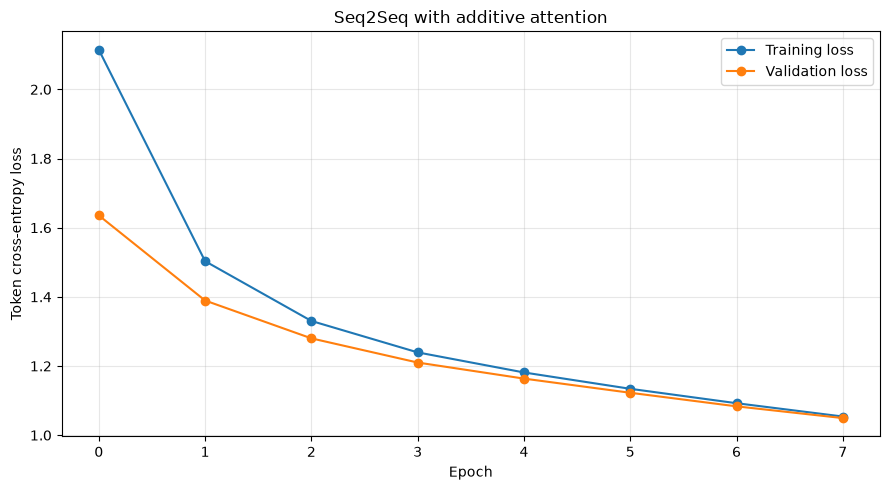

In [13]:
plt.figure(figsize=(9, 5))
plt.plot(train_losses, marker="o", label="Training loss")
plt.plot(valid_losses, marker="o", label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Token cross-entropy loss")
plt.title("Seq2Seq with additive attention")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


In [14]:
@torch.no_grad()
def teacher_forced_token_accuracy(model, loader):
    model.eval()
    correct, total = 0, 0
    for src, src_lengths, tgt, _, _ in loader:
        src, tgt = src.to(DEVICE), tgt.to(DEVICE)
        logits, _ = model(src, src_lengths, tgt[:, :-1])
        predictions = logits.argmax(dim=-1)
        labels = tgt[:, 1:]
        mask = labels.ne(model.tgt_pad_id)
        correct += ((predictions == labels) & mask).sum().item()
        total += mask.sum().item()
    return correct / max(total, 1)

accuracy = teacher_forced_token_accuracy(model, test_loader)
print(f"Test teacher-forced token accuracy: {accuracy:.3f}")

for source, reference in test_pairs[:8]:
    prediction, _, _, _ = model.translate(source, src_vocab, tgt_vocab)
    print("\nEN:  ", source)
    print("REF: ", reference)
    print("PRED:", prediction)


Test teacher-forced token accuracy: 0.702

EN:   A man in an orange hat starring at something.
REF:  Ein Mann mit einem orangefarbenen Hut, der etwas anstarrt.
PRED: e i n   m a n n   i n   e i n e m   f a h r r a d   a u f   e i n e m

EN:   A Boston Terrier is running on lush green grass in front of a white fence.
REF:  Ein Boston Terrier läuft über saftig-grünes Gras vor einem weißen Zaun.
PRED: e i n   b a u m e n   v o r   e i n e m   g r o ß e n   g r o ß e n  

EN:   A girl in karate uniform breaking a stick with a front kick.
REF:  Ein Mädchen in einem Karateanzug bricht ein Brett mit einem Tritt.
PRED: e i n   m ä d c h e n   i n   e i n e m   k a m e r a   m i t   e i n

EN:   Five people wearing winter jackets and helmets stand in the snow, with snowmobiles in the background.
REF:  Fünf Leute in Winterjacken und mit Helmen stehen im Schnee mit Schneemobilen im Hintergrund.
PRED: f r a u e n   m i t   e i n e m   b a n k   i n   e i n e m   b a n k

EN:   People are fixing th

Source:     A man in an orange hat starring at something.
Reference:  Ein Mann mit einem orangefarbenen Hut, der etwas anstarrt.
Prediction: e i n   m a n n   i n   e i n e m   f a h r r a d   a u f   e i n e m


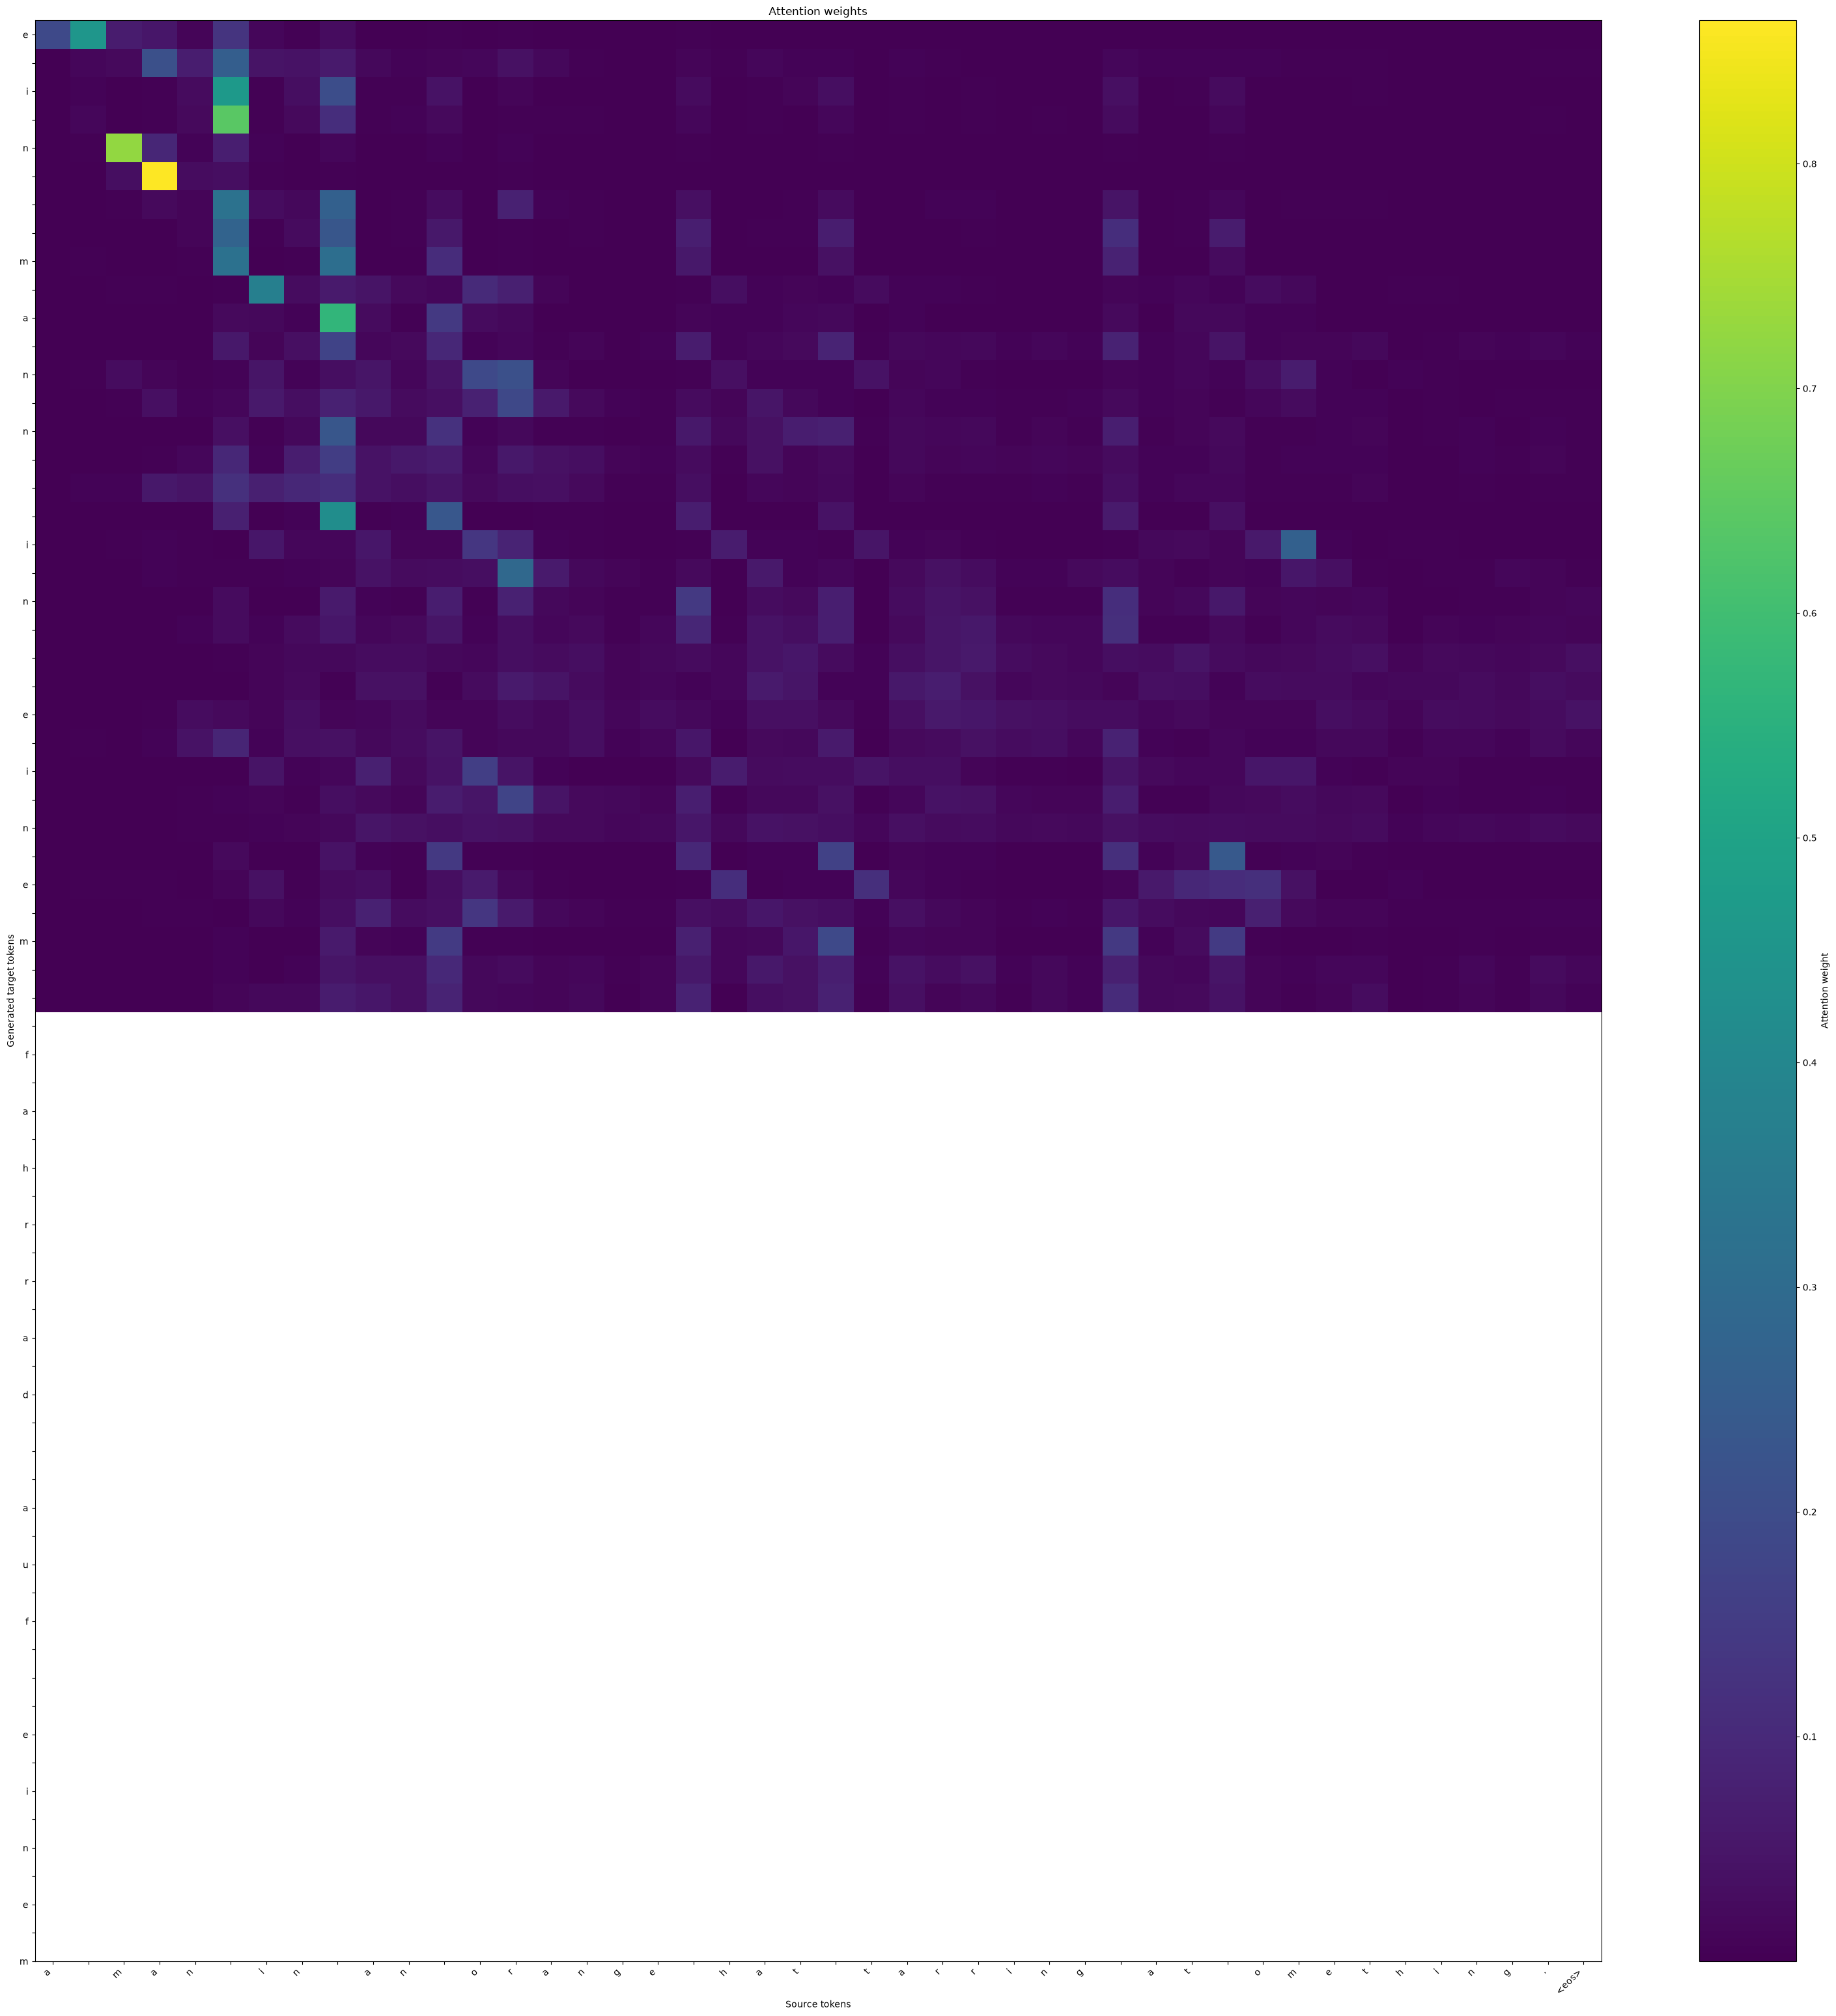

In [15]:
def plot_attention(source_tokens, target_tokens, attention_matrix):
    if attention_matrix.size == 0 or len(target_tokens) == 0:
        print("No attention values to plot.")
        return

    # The final attention row may correspond to predicting <eos>.
    matrix = attention_matrix[:len(target_tokens), :len(source_tokens)]

    fig, ax = plt.subplots(
        figsize=(max(7, len(source_tokens) * 0.7),
                 max(4, len(target_tokens) * 0.45))
    )
    image = ax.imshow(matrix, aspect="auto", cmap="viridis")
    ax.set_xticks(range(len(source_tokens)))
    ax.set_xticklabels(source_tokens, rotation=45, ha="right")
    ax.set_yticks(range(len(target_tokens)))
    ax.set_yticklabels(target_tokens)
    ax.set_xlabel("Source tokens")
    ax.set_ylabel("Generated target tokens")
    ax.set_title("Attention weights")
    fig.colorbar(image, ax=ax, label="Attention weight")
    fig.tight_layout()
    plt.show()

source, reference = test_pairs[0]
prediction, attention_matrix, source_tokens, predicted_tokens = model.translate(
    source, src_vocab, tgt_vocab
)

print("Source:    ", source)
print("Reference: ", reference)
print("Prediction:", prediction)

plot_attention(source_tokens, predicted_tokens, attention_matrix)


English: a man is riding a bicycle
German: e i n   m a n n   i n   r o t e r   r a d f a h r e r   r e i t e t  


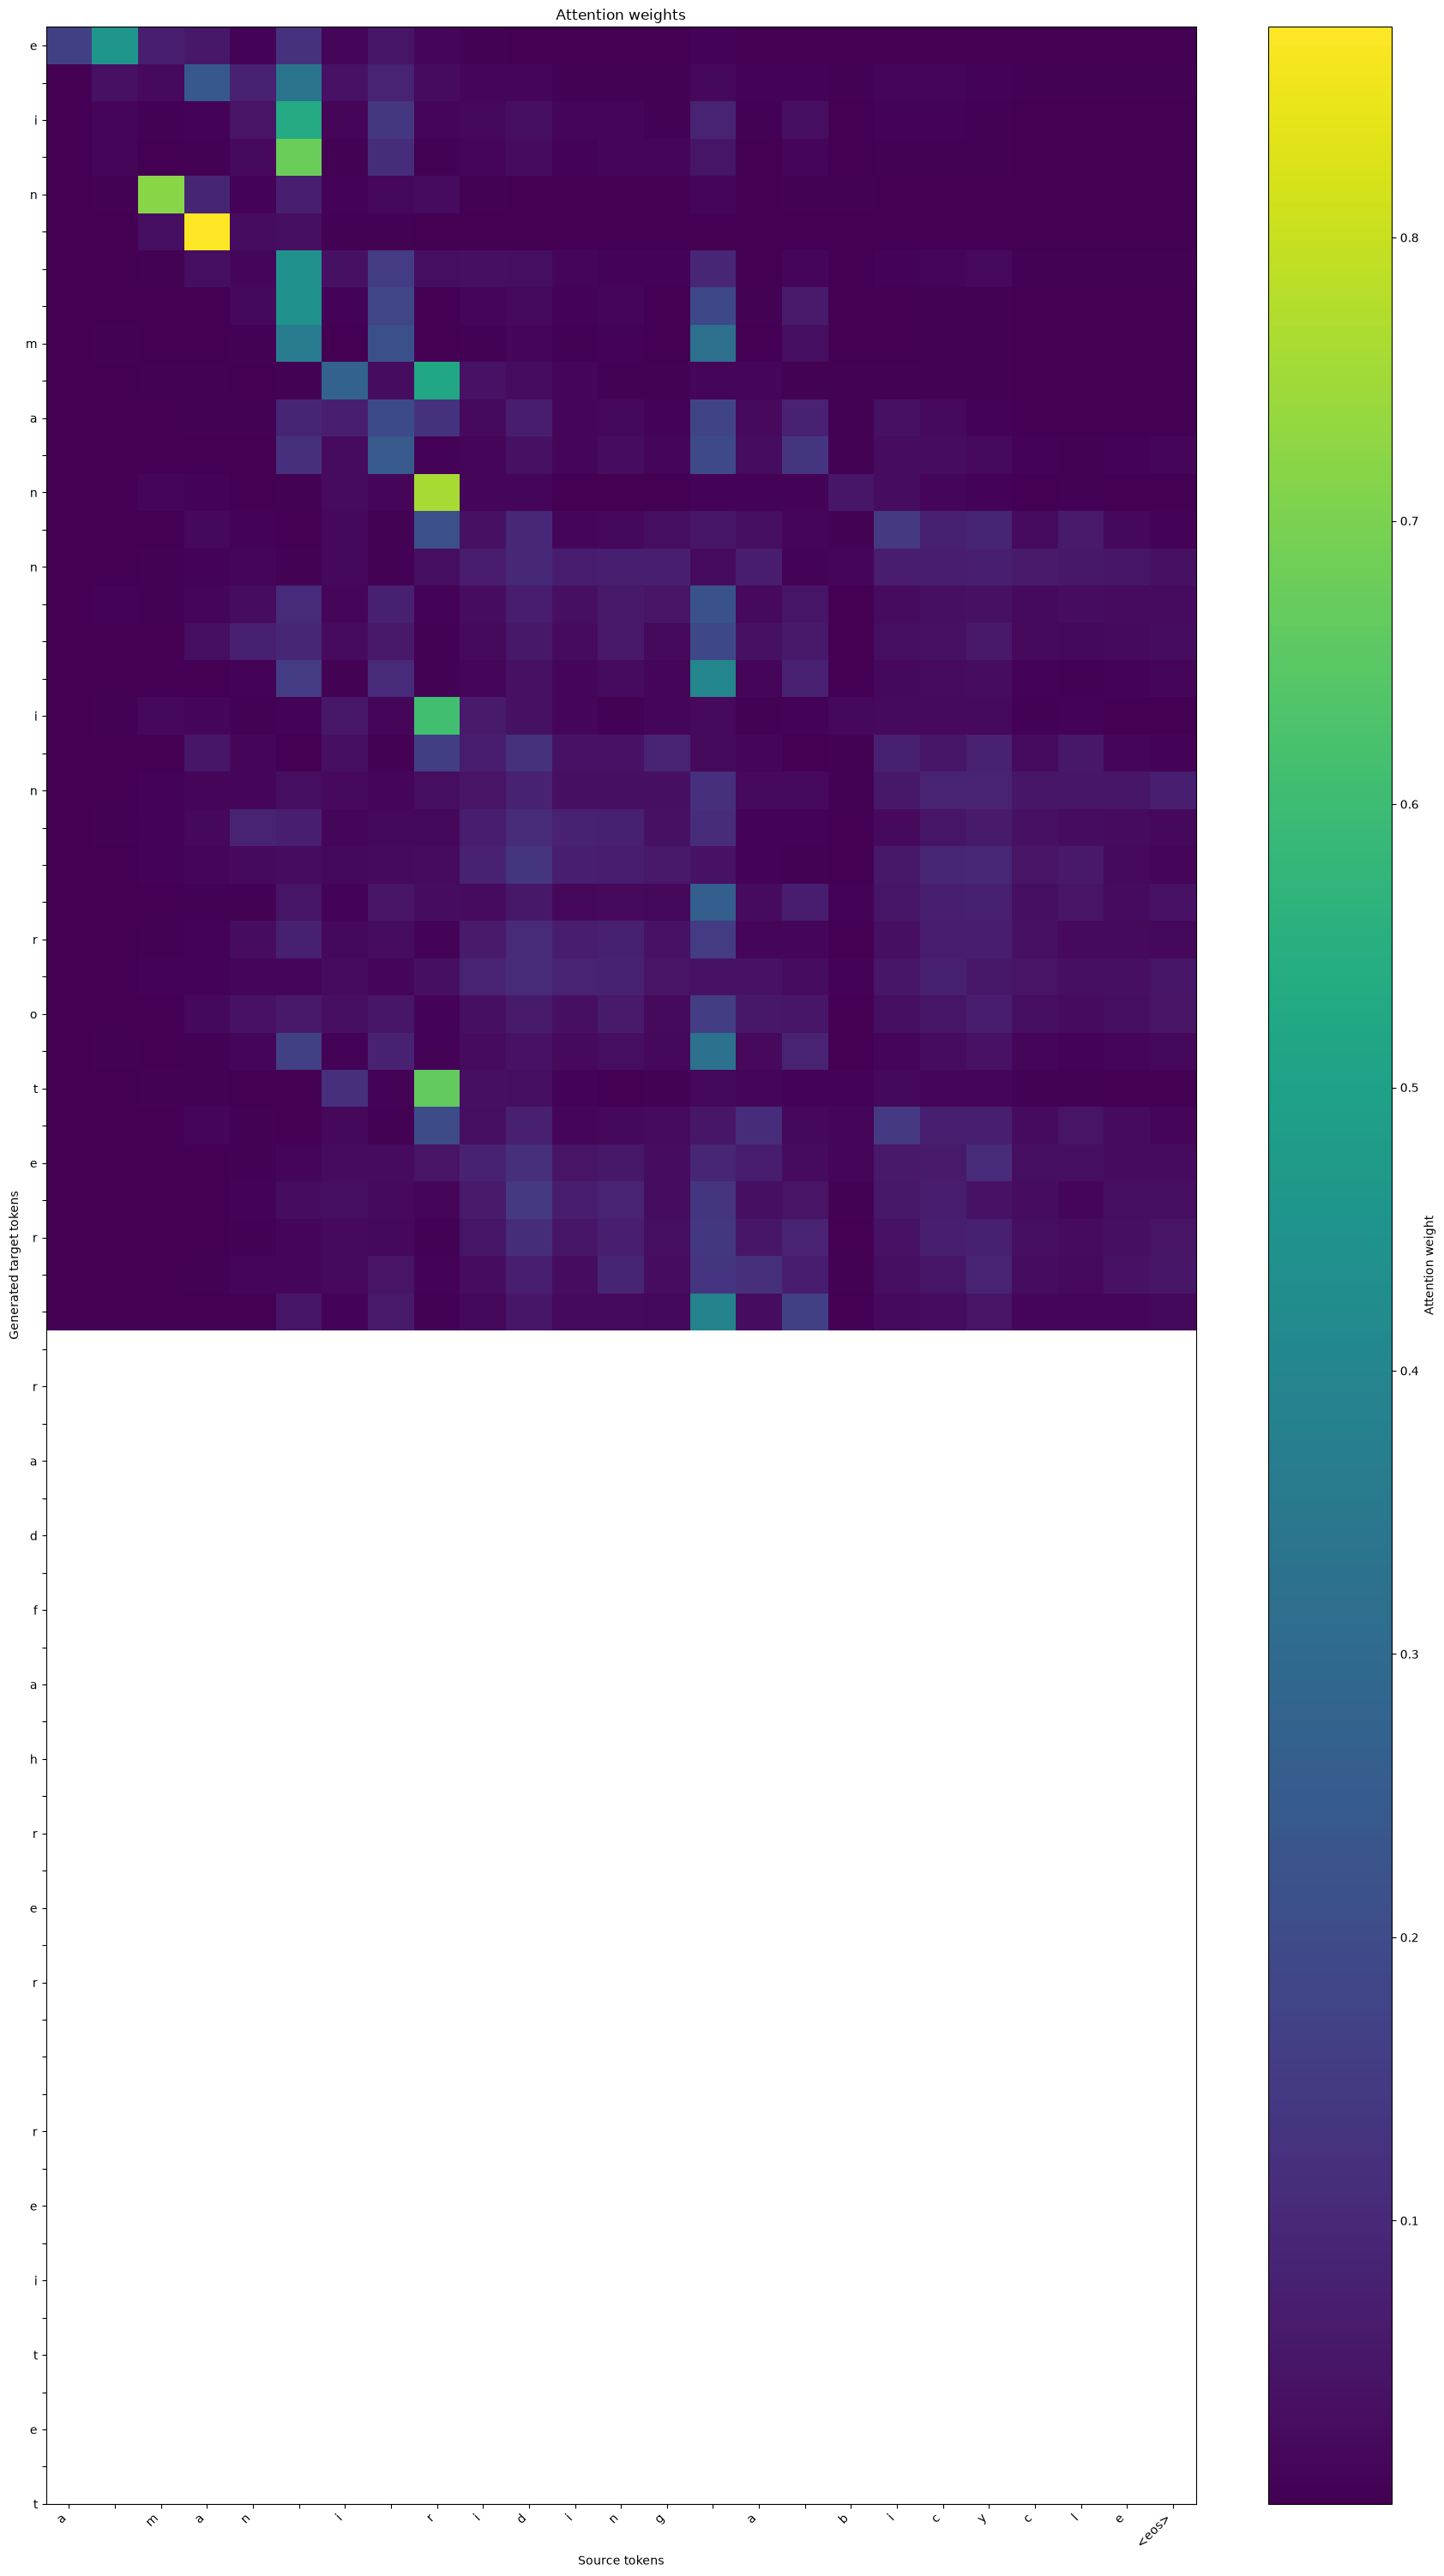

In [16]:
custom_sentence = "a man is riding a bicycle"

prediction, attention_matrix, source_tokens, predicted_tokens = model.translate(
    custom_sentence, src_vocab, tgt_vocab
)

print("English:", custom_sentence)
print("German:", prediction)
plot_attention(source_tokens, predicted_tokens, attention_matrix)
